# Modelos de clasificación — Predicción de propensión de compra

**Machine Learning para la toma de decisiones — Sesión 3**
Universidad del Pacífico

---

Este cuaderno recorre el ciclo completo de un modelo de clasificación aplicado a un caso de negocio:
comprender los datos → limpiar → explorar → **entrenar el primer modelo** → **evaluar sus indicadores en train y test** → decidir.

> **Regla del curso:** ningún indicador se reporta solo en *test*. Siempre se compara **train vs. test**,
> porque la diferencia entre ambos es lo que nos dice si el modelo aprendió o si solo memorizó.

## 0. Contexto de negocio

### La empresa

**Vitrina** es un retailer omnicanal peruano (moda, electrónica, hogar, belleza y deportes) que vende a través
de su tienda web y de 22 locales en Lima y provincias. El equipo de *Growth* trabaja con una base de
**1,500 clientes perfilados**: personas que crearon cuenta, navegaron el catálogo y dejaron rastro de
comportamiento, pero de las cuales solo una parte terminó comprando en la campaña anterior.

### El problema

Cada semana, el equipo comercial puede contactar a **150 clientes** como máximo. Ese es el techo real:
capacidad del *contact center*, presupuesto de cupones y fatiga del canal (si se envía a todos, la tasa de
apertura se desploma y el dominio empieza a caer en spam).

Hoy la lista de 150 se arma **a dedo o al azar**. Como el 47% de la base compra, contactar 150 clientes
sin criterio produce aproximadamente **70 compradores**. La pregunta del gerente comercial es directa:

> *"¿Podemos usar los datos que ya tenemos para elegir mejor a esos 150?"*

### La pregunta analítica

Traducida a lenguaje de modelo:

| Elemento | Definición |
|---|---|
| **Tarea** | Clasificación binaria supervisada |
| **Variable objetivo** | `PurchaseStatus` — 1 si el cliente compró, 0 si no |
| **Unidad de análisis** | Un cliente |
| **Predictores** | Demografía, ingresos, historial de compra y comportamiento en el sitio web |
| **Entregable** | Un *score* de 0 a 1 por cliente, que permita **ordenar** la base de mayor a menor propensión |

### Qué error duele más

Las dos formas de equivocarse **no cuestan lo mismo** (recordar los errores Tipo I y Tipo II de la sesión):

- **Falso positivo** — contactamos a alguien que no iba a comprar. Cuesta un cupón y un espacio de la lista de 150.
- **Falso negativo** — dejamos fuera a alguien que sí iba a comprar. Cuesta el margen completo de esa venta.

Con capacidad limitada, el falso negativo es más caro: cada espacio mal asignado desplaza a un comprador real.
Esto tendrá consecuencias concretas cuando elijamos el **punto de corte** en la sección 10.

### Criterio de éxito

El modelo se considera útil si la lista de 150 clientes que produce **duplica** la tasa de conversión
de una lista armada al azar, y si su desempeño en *test* no se derrumba respecto de *train*.

> **Nota de honestidad analítica.** Un modelo de propensión responde *"¿quién va a comprar?"*, no
> *"¿a quién lo convence mi campaña?"*. Son preguntas distintas: la segunda requiere un diseño experimental
> con grupo de control (*uplift modeling*). En este caso el objetivo es priorizar una capacidad escasa,
> y para eso el ordenamiento por propensión es la herramienta correcta.

## 1. Preparación del entorno

### 1.1 Librerías

In [ ]:
# Manipulación y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Preparación y partición
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Modelos de clasificación
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings('ignore')

### 1.2 Parámetros globales

Fijar una sola semilla al inicio y reutilizarla en todo el cuaderno es lo que hace que los resultados
sean **reproducibles**: si un alumno corre esta celda mañana, obtiene exactamente los mismos números.

In [ ]:
SEMILLA   = 42     # random_state único para todo el cuaderno
TEST_SIZE = 0.30   # 30% de los datos se reservan para evaluación
TARGET    = 'PurchaseStatus'

# Paleta institucional
AZUL, AZUL_CLARO, GRIS, AMBAR = '#0F2B5B', '#2E75D4', '#9AA5B1', '#E8A33D'

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']  = 110
plt.rcParams['font.size']   = 11
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

### 1.3 Caja de herramientas

En lugar de repetir el mismo bloque de `matplotlib` diez veces, definimos las funciones **una vez** aquí
y las reutilizamos en todo el cuaderno. Esto no es cosmética: reduce el riesgo de que un gráfico quede
desactualizado respecto de otro y hace que agregar un cuarto modelo cueste una línea en vez de cuarenta.

In [ ]:
# ══════════════════════════════════════════════════════════════════
#  A. Funciones de exploración
# ══════════════════════════════════════════════════════════════════

def resumen_frecuencias(df, columnas):
    """Tabla de frecuencia y porcentaje para cada variable categórica."""
    for col in columnas:
        frec = df[col].value_counts(dropna=False)
        tabla = pd.DataFrame({
            'Frecuencia': frec,
            'Porcentaje (%)': (frec / len(df) * 100).round(2)
        })
        print(f'── {col} ' + '─' * (60 - len(col)))
        print(tabla.to_string(), '\n')


def graficar_categoricas(df, columnas, n_cols=3):
    """Barras con porcentaje anotado para un conjunto de variables categóricas."""
    n_filas = math.ceil(len(columnas) / n_cols)
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(5.5 * n_cols, 4 * n_filas))
    axes = np.atleast_1d(axes).flatten()

    for ax, col in zip(axes, columnas):
        conteo = df[col].value_counts()
        conteo.plot(kind='bar', ax=ax, color=AZUL, edgecolor='white')
        ax.set_title(col, fontweight='bold')
        ax.set_ylabel('Clientes')
        ax.tick_params(axis='x', rotation=30)
        for p in ax.patches:
            ax.annotate(f'{100 * p.get_height() / len(df):.1f}%',
                        (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=9)

    for ax in axes[len(columnas):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


def graficar_numericas(df, columnas, n_cols=2, bins=30):
    """Histograma + boxplot apilados para cada variable numérica."""
    n_filas = math.ceil(len(columnas) / n_cols)
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(6.5 * n_cols, 4 * n_filas))
    axes = np.atleast_1d(axes).flatten()

    for ax, col in zip(axes, columnas):
        ax.hist(df[col], bins=bins, color=AZUL, edgecolor='white')
        ax.set_title(f'Distribución de {col}', fontweight='bold')
        ax.set_xlabel(col); ax.set_ylabel('Frecuencia')
        ax.axvline(df[col].mean(), color=AMBAR, ls='--', lw=2,
                   label=f'Media = {df[col].mean():,.1f}')
        ax.legend(fontsize=9)

    for ax in axes[len(columnas):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


def boxplots_por_target(df, columnas, target, n_cols=2):
    """Compara la distribución de cada variable numérica entre las dos clases."""
    n_filas = math.ceil(len(columnas) / n_cols)
    fig, axes = plt.subplots(n_filas, n_cols, figsize=(6 * n_cols, 4 * n_filas))
    axes = np.atleast_1d(axes).flatten()

    for ax, col in zip(axes, columnas):
        sns.boxplot(x=df[target], y=df[col], ax=ax,
                    palette=[GRIS, AZUL], linewidth=1.2)
        ax.set_title(f'{col} según {target}', fontweight='bold')
        ax.set_xlabel(f'0 = No compra   |   1 = Compra')

    for ax in axes[len(columnas):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


def tasa_por_categoria(df, columna, target, ax=None):
    """Tasa de la clase positiva por categoría, contra la tasa global."""
    tasa   = df.groupby(columna, observed=True)[target].mean().sort_values(ascending=False)
    global_ = df[target].mean()

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    colores = [AZUL if v >= global_ else GRIS for v in tasa.values]
    tasa.plot(kind='bar', ax=ax, color=colores, edgecolor='white')
    ax.axhline(global_, color=AMBAR, ls='--', lw=2,
               label=f'Tasa global = {global_:.1%}')
    ax.set_title(f'Tasa de compra por {columna}', fontweight='bold')
    ax.set_ylabel('% que compra'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=9)
    for p in ax.patches[:len(tasa)]:
        ax.annotate(f'{p.get_height():.0%}',
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
    if ax is None:
        plt.tight_layout(); plt.show()
    return tasa

In [ ]:
# ══════════════════════════════════════════════════════════════════
#  B. Funciones de evaluación  ←  el núcleo del cuaderno
# ══════════════════════════════════════════════════════════════════

def calcular_metricas(y_real, y_pred, y_proba):
    """
    Devuelve las 8 métricas vistas en clase a partir de la matriz de confusión.

        Accuracy      = (TP + TN) / total
        Precision     = TP / (TP + FP)
        Recall        = TP / (TP + FN)      ← sensibilidad
        Especificidad = TN / (TN + FP)
        F1            = media armónica de precision y recall
        AUC           = área bajo la curva ROC
        Gini          = 2 · AUC − 1
    """
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    auc = roc_auc_score(y_real, y_proba)
    return {
        'Accuracy':      accuracy_score(y_real, y_pred),
        'Precision':     precision_score(y_real, y_pred, zero_division=0),
        'Recall':        recall_score(y_real, y_pred),
        'Especificidad': tn / (tn + fp),
        'F1':            f1_score(y_real, y_pred),
        'AUC':           auc,
        'Gini':          2 * auc - 1,
    }


def evaluar_modelo(modelo, X_tr, y_tr, X_te, y_te, nombre, umbral=0.5, entrenar=True):
    """
    Entrena (opcional) y evalúa un clasificador SIEMPRE en train y en test.

    Devuelve un DataFrame de 2 filas — Train y Test — con las 8 métricas,
    para que la comparación entre ambas sea imposible de omitir.
    """
    if entrenar:
        modelo.fit(X_tr, y_tr)

    filas = {}
    for etiqueta, (X, y) in {'Train': (X_tr, y_tr), 'Test': (X_te, y_te)}.items():
        proba = modelo.predict_proba(X)[:, 1]
        pred  = (proba >= umbral).astype(int)
        filas[etiqueta] = calcular_metricas(y, pred, proba)

    res = pd.DataFrame(filas).T
    res.index.name = 'Partición'
    res.insert(0, 'Modelo', nombre)
    return res


def diagnostico_sobreajuste(resultado, metrica='Accuracy', tolerancia=0.05):
    """
    Traduce la brecha train − test a un veredicto legible.
    Una brecha > 5 puntos es la señal clásica de sobreajuste.
    """
    tr, te = resultado.loc['Train', metrica], resultado.loc['Test', metrica]
    brecha = tr - te
    if brecha > tolerancia:
        veredicto = '⚠️  SOBREAJUSTE — el modelo memorizó el train'
    elif brecha < -tolerancia:
        veredicto = '🔎 Test mejor que train — revisar la partición'
    else:
        veredicto = '✅ Generaliza bien — la brecha es aceptable'
    print(f'{metrica:<14} Train = {tr:.3f}   Test = {te:.3f}   '
          f'Brecha = {brecha:+.3f}\n{veredicto}')
    return brecha


def graficar_matrices_confusion(modelo, X_tr, y_tr, X_te, y_te, nombre, umbral=0.5):
    """Matrices de confusión de train y test, lado a lado y en la misma escala."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

    for ax, etiqueta, (X, y) in zip(axes, ['Train', 'Test'],
                                    [(X_tr, y_tr), (X_te, y_te)]):
        pred = (modelo.predict_proba(X)[:, 1] >= umbral).astype(int)
        cm   = confusion_matrix(y, pred)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    linewidths=1.2, linecolor='white', annot_kws={'size': 14},
                    xticklabels=['Pred. 0', 'Pred. 1'],
                    yticklabels=['Real 0', 'Real 1'])
        acc = accuracy_score(y, pred)
        ax.set_title(f'{etiqueta} — Accuracy {acc:.3f}', fontweight='bold')

    fig.suptitle(f'Matriz de confusión — {nombre}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


def graficar_roc(modelo, X_tr, y_tr, X_te, y_te, nombre):
    """Curvas ROC de train y test superpuestas: si se separan mucho, hay sobreajuste."""
    plt.figure(figsize=(6.5, 5.5))
    plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Azar (AUC = 0.500)')

    for etiqueta, (X, y), color in zip(['Train', 'Test'],
                                       [(X_tr, y_tr), (X_te, y_te)],
                                       [GRIS, AZUL]):
        proba = modelo.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, proba)
        auc = roc_auc_score(y, proba)
        plt.plot(fpr, tpr, color=color, lw=2.2,
                 label=f'{etiqueta} — AUC = {auc:.3f}')

    plt.xlabel('Tasa de falsos positivos  (1 − especificidad)')
    plt.ylabel('Tasa de verdaderos positivos  (recall)')
    plt.title(f'Curva ROC — {nombre}', fontweight='bold')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def graficar_importancias(valores, columnas, titulo, xlabel='Importancia'):
    """Ranking horizontal de variables (sirve para feature_importances_ y para coeficientes)."""
    imp = (pd.DataFrame({'Variable': columnas, 'Valor': valores})
             .assign(abs_val=lambda d: d['Valor'].abs())
             .sort_values('abs_val', ascending=False))

    plt.figure(figsize=(8, 0.55 * len(imp) + 1.5))
    colores = [AZUL if v >= 0 else AMBAR for v in imp['Valor']]
    plt.barh(imp['Variable'], imp['Valor'], color=colores, edgecolor='white')
    plt.gca().invert_yaxis()
    plt.xlabel(xlabel)
    plt.title(titulo, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return imp.drop(columns='abs_val').reset_index(drop=True)

In [ ]:
# ══════════════════════════════════════════════════════════════════
#  C. Funciones de decisión de negocio
# ══════════════════════════════════════════════════════════════════

def barrido_umbral(y_real, y_proba, umbrales=np.arange(0.1, 0.95, 0.05)):
    """
    Recalcula las métricas para distintos puntos de corte.
    El modelo es uno solo; lo que cambia es la regla de decisión.
    """
    filas = []
    for u in umbrales:
        pred = (y_proba >= u).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, pred).ravel()
        filas.append({
            'Umbral':    round(u, 2),
            'Contactados': int(pred.sum()),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Precision': precision_score(y_real, pred, zero_division=0),
            'Recall':    recall_score(y_real, pred),
            'F1':        f1_score(y_real, pred),
        })
    return pd.DataFrame(filas)


def tabla_deciles(y_real, y_proba, n=10):
    """
    Ordena la base por score, la parte en deciles y calcula el lift de cada uno.
    Es la forma estándar de presentar un modelo a un área comercial.
    """
    d = pd.DataFrame({'score': y_proba, 'real': np.asarray(y_real)})
    d['Decil'] = pd.qcut(d['score'].rank(method='first'), n,
                         labels=range(1, n + 1))  # 1 = mayor score
    d['Decil'] = (n + 1) - d['Decil'].astype(int)

    tabla = (d.groupby('Decil')
               .agg(Clientes=('real', 'size'),
                    Compradores=('real', 'sum'),
                    Tasa_compra=('real', 'mean'),
                    Score_min=('score', 'min'),
                    Score_max=('score', 'max'))
               .sort_index())
    tasa_global = d['real'].mean()
    tabla['Lift']            = tabla['Tasa_compra'] / tasa_global
    tabla['Captura_acum_%']  = tabla['Compradores'].cumsum() / tabla['Compradores'].sum() * 100
    return tabla

## 2. Comprensión de los datos

### 2.1 Carga del dataset

In [ ]:
# Funciona igual en Google Colab que en local
import pandas as pd
RUTA = 'customer_purchase_data.csv'

df = pd.read_csv("/content/customer_purchase_data.csv")

print(f'Filas: {df.shape[0]:,}   |   Columnas: {df.shape[1]}')
df.info()

Filas: 1,500   |   Columnas: 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   TimeSpentOnWebsite  1500 non-null   float64
 6   LoyaltyProgram      1500 non-null   int64  
 7   DiscountsAvailed    1500 non-null   int64  
 8   PurchaseStatus      1500 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 105.6 KB


In [ ]:
df.head()

,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus
0,40,1,"66,120.2679",8,0,30.5686,0,5,1
1,20,1,"23,579.7736",4,2,38.2401,0,5,0
2,27,1,"127,821.3064",11,2,31.6332,1,0,1
3,24,1,"137,798.6231",19,3,46.1671,0,4,1
4,31,1,"99,300.9642",19,1,19.8236,0,0,1


### 2.2 Diccionario de datos

| Variable | Descripción | Tipo |
|---|---|---|
| `Age` | Edad del cliente | Numérica |
| `Gender` | Género — 0: masculino, 1: femenino | Categórica binaria |
| `AnnualIncome` | Ingreso anual en dólares | Numérica |
| `NumberOfPurchases` | Compras históricas acumuladas | Numérica |
| `ProductCategory` | Categoría del último producto — 0: Electrónica, 1: Ropa, 2: Hogar, 3: Belleza, 4: Deportes | Categórica |
| `TimeSpentOnWebsite` | Minutos en el sitio web | Numérica |
| `LoyaltyProgram` | Miembro del programa de fidelización — 0: No, 1: Sí | Categórica binaria |
| `DiscountsAvailed` | Descuentos utilizados (0 a 5) | Numérica discreta |
| **`PurchaseStatus`** | **Variable objetivo** — 1: compró, 0: no compró | **Binaria** |



```
# Esto tiene formato de código
```

### 2.3 Etiquetas legibles

Los códigos numéricos sirven al modelo pero no al análisis. Creamos columnas con etiquetas
**solo para explorar y graficar**; antes de modelar las quitamos, porque el modelo ya tiene esa
información en las columnas originales.

In [ ]:
MAPA_CATEGORIA = {0: 'Electrónica', 1: 'Ropa', 2: 'Hogar', 3: 'Belleza', 4: 'Deportes'}
MAPA_GENERO    = {0: 'Masculino', 1: 'Femenino'}
MAPA_COMPRA    = {0: 'No compra', 1: 'Compra'}

df['CategoriaLabel'] = df['ProductCategory'].map(MAPA_CATEGORIA).astype('category')
df['GeneroLabel']    = df['Gender'].map(MAPA_GENERO).astype('category')

COLS_ETIQUETA = ['CategoriaLabel', 'GeneroLabel']   # se eliminan antes de modelar (se crear una version que sea más facil de
# analizar dado que para la parte del modelado si se necesitan los números).

df[['ProductCategory', 'CategoriaLabel', 'Gender', 'GeneroLabel']].head()

,ProductCategory,CategoriaLabel,Gender,GeneroLabel
0,0,Electrónica,1,Femenino
1,2,Hogar,1,Femenino
2,2,Hogar,1,Femenino
3,3,Belleza,1,Femenino
4,1,Ropa,1,Femenino


## 3. Limpieza inicial

Dos verificaciones obligatorias antes de cualquier análisis: **valores nulos** y **registros duplicados**.

### 3.1 Valores nulos

In [ ]:
nulos = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    '% del total': (df.isnull().sum() / len(df) * 100).round(2)
})
print(nulos.to_string())
print(f'\nTotal de valores nulos en el dataset: {df.isnull().sum().sum()}')

                    Nulos  % del total
Age                     0       0.0000
Gender                  0       0.0000
AnnualIncome            0       0.0000
NumberOfPurchases       0       0.0000
ProductCategory         0       0.0000
TimeSpentOnWebsite      0       0.0000
LoyaltyProgram          0       0.0000
DiscountsAvailed        0       0.0000
PurchaseStatus          0       0.0000
CategoriaLabel          0       0.0000
GeneroLabel             0       0.0000

Total de valores nulos en el dataset: 0


No hay valores faltantes: no se requiere imputación ni eliminación de registros por esta causa.

### 3.2 Registros duplicados

Un cliente duplicado se cuenta dos veces al entrenar. Peor aún: si una de sus copias cae en *train*
y la otra en *test*, el modelo estará evaluándose sobre un registro que ya vio, y su desempeño
en test se verá **artificialmente inflado**. Por eso se eliminan **antes** de partir los datos.

In [ ]:
n_dup = df.duplicated().sum()
print(f'Registros duplicados: {n_dup}  ({n_dup / len(df):.1%} de la base)')

df = df.drop_duplicates().reset_index(drop=True)
print(f'Filas tras eliminar duplicados: {len(df):,}')
print(f'Duplicados restantes: {df.duplicated().sum()}')

Registros duplicados: 112  (7.5% de la base)
Filas tras eliminar duplicados: 1,388
Duplicados restantes: 0


## 4. Análisis exploratorio

El objetivo no es hacer gráficos bonitos, sino llegar al modelado sabiendo **qué esperar**:
qué variables deberían pesar y cuál es el balance de la variable objetivo.

### 4.1 La variable objetivo

Antes que nada: ¿cuán balanceadas están las clases? Si una clase representara el 2% de la base,
un modelo que prediga siempre "no compra" tendría 98% de accuracy y sería completamente inútil.

In [ ]:
balance = df[TARGET].value_counts().rename(index=MAPA_COMPRA)
print(pd.DataFrame({
    'Clientes': balance,
    '%': (balance / len(df) * 100).round(1)
}).to_string())

TASA_GLOBAL = df[TARGET].mean()
print(f'\nTasa global de compra: {TASA_GLOBAL:.1%}')
print('→ Clases razonablemente balanceadas: accuracy es una métrica interpretable en este caso.')

                Clientes       %
PurchaseStatus                  
No compra            740 53.3000
Compra               648 46.7000

Tasa global de compra: 46.7%
→ Clases razonablemente balanceadas: accuracy es una métrica interpretable en este caso.


### 4.2 Variables categóricas

In [ ]:
COLS_CAT = ['GeneroLabel', 'CategoriaLabel', 'LoyaltyProgram', 'DiscountsAvailed']

resumen_frecuencias(df, COLS_CAT)

── GeneroLabel ─────────────────────────────────────────────────
             Frecuencia  Porcentaje (%)
GeneroLabel                            
Femenino            696         50.1400
Masculino           692         49.8600 

── CategoriaLabel ──────────────────────────────────────────────
                Frecuencia  Porcentaje (%)
CategoriaLabel                            
Ropa                   306         22.0500
Deportes               289         20.8200
Belleza                270         19.4500
Electrónica            269         19.3800
Hogar                  254         18.3000 

── LoyaltyProgram ──────────────────────────────────────────────
                Frecuencia  Porcentaje (%)
LoyaltyProgram                            
0                      925         66.6400
1                      463         33.3600 

── DiscountsAvailed ────────────────────────────────────────────
                  Frecuencia  Porcentaje (%)
DiscountsAvailed                            
4          

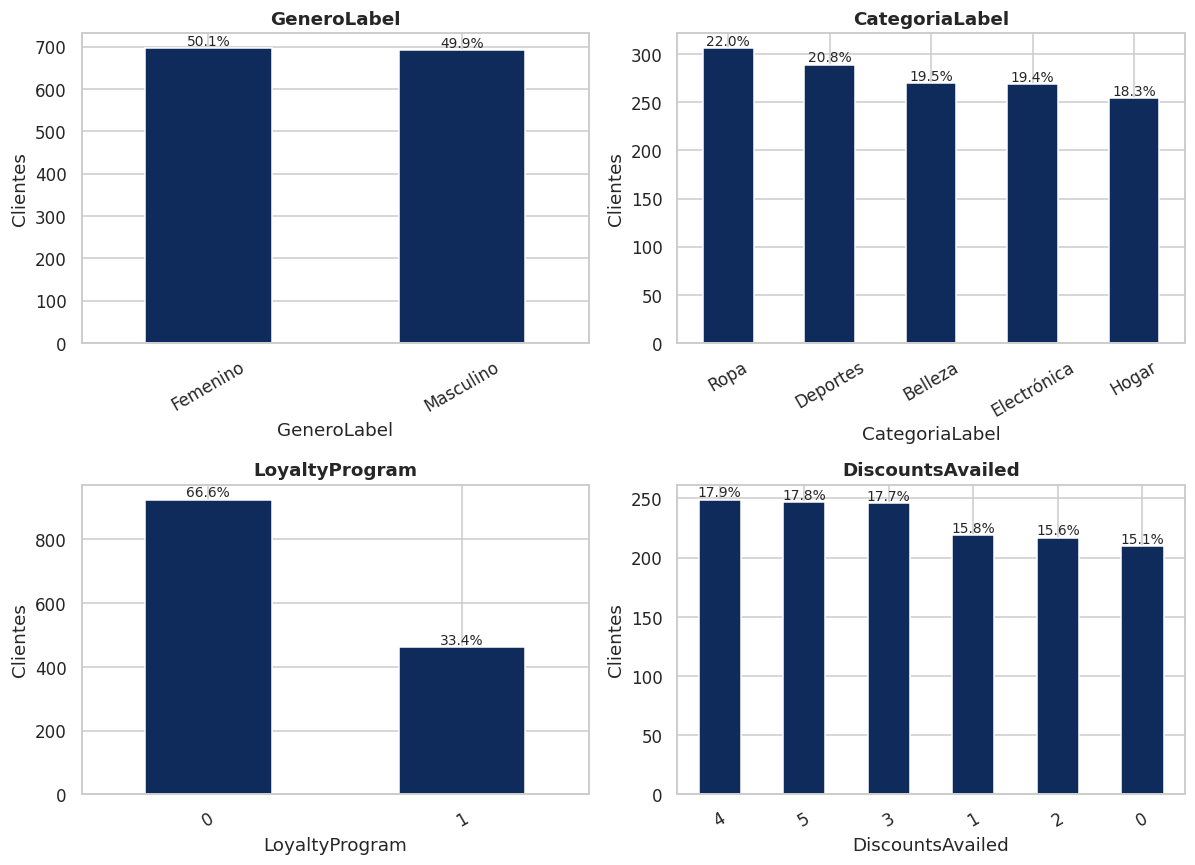

In [ ]:
graficar_categoricas(df, COLS_CAT, n_cols=2)

### 4.3 Variables numéricas

In [ ]:
COLS_NUM = ['Age', 'AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite']

df[COLS_NUM].describe().T # permite ver una vista general de mis datos.

,count,mean,std,min,25%,50%,75%,max
Age,"1,388.0000",43.9395,15.4875,18.0000,30.7500,44.0000,57.0000,70.0000
AnnualIncome,"1,388.0000","84,699.0454","37,541.1365","20,001.5125","53,766.8958","84,625.2929","117,188.2080","149,785.1765"
NumberOfPurchases,"1,388.0000",10.5490,5.8694,0.0000,6.0000,11.0000,15.0000,20.0000
TimeSpentOnWebsite,"1,388.0000",30.7475,16.9769,1.0370,16.3796,31.2131,44.6664,59.9911


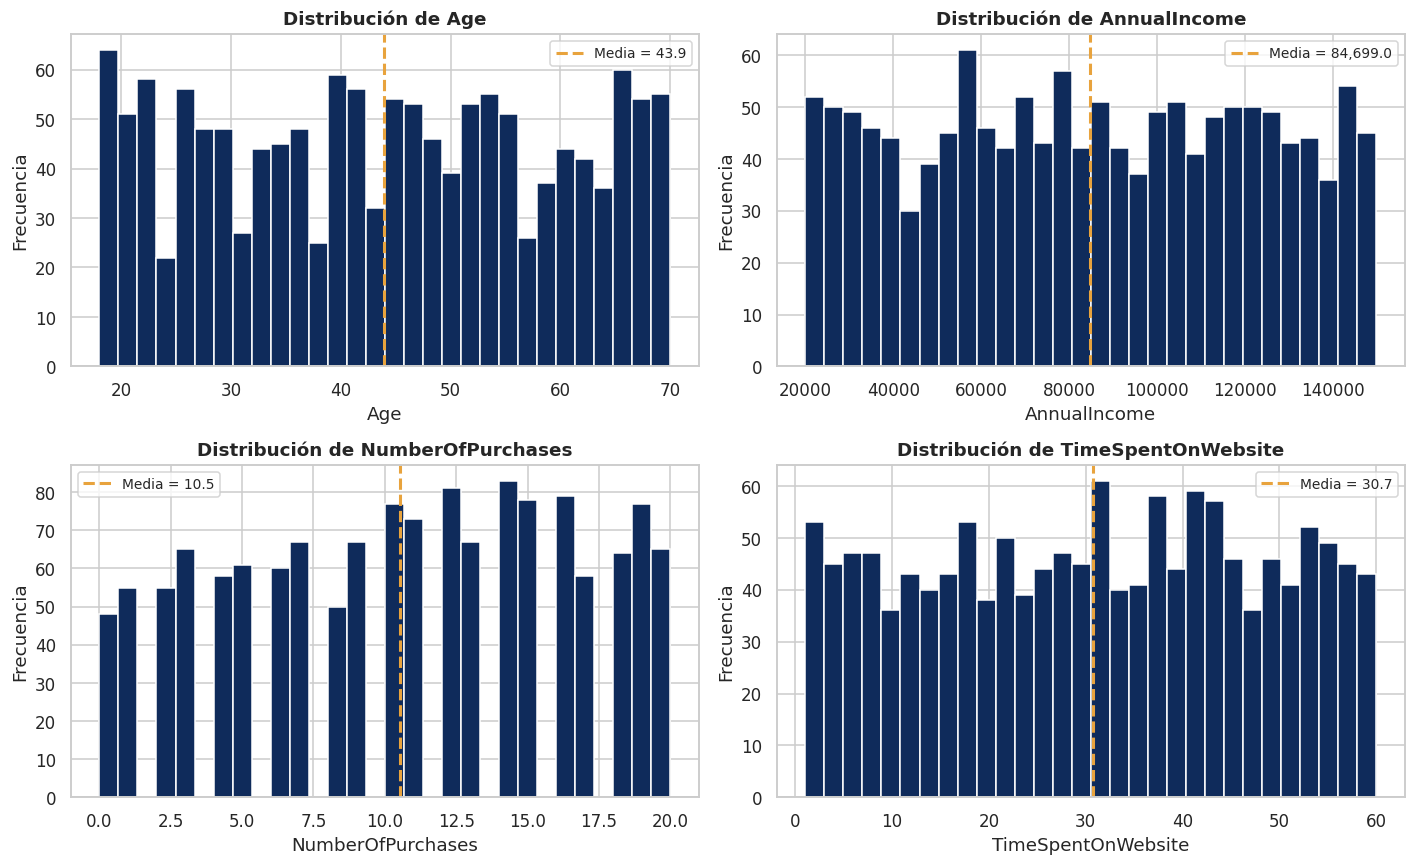

In [ ]:
graficar_numericas(df, COLS_NUM, n_cols=2)

Las cuatro variables numéricas se distribuyen de forma aproximadamente uniforme y no presentan
valores extremos que requieran tratamiento.

### 4.4 Análisis bivariado

Aquí es donde empezamos a intuir qué variables tendrán poder predictivo: buscamos aquellas cuya
distribución **cambia** entre quienes compran y quienes no.

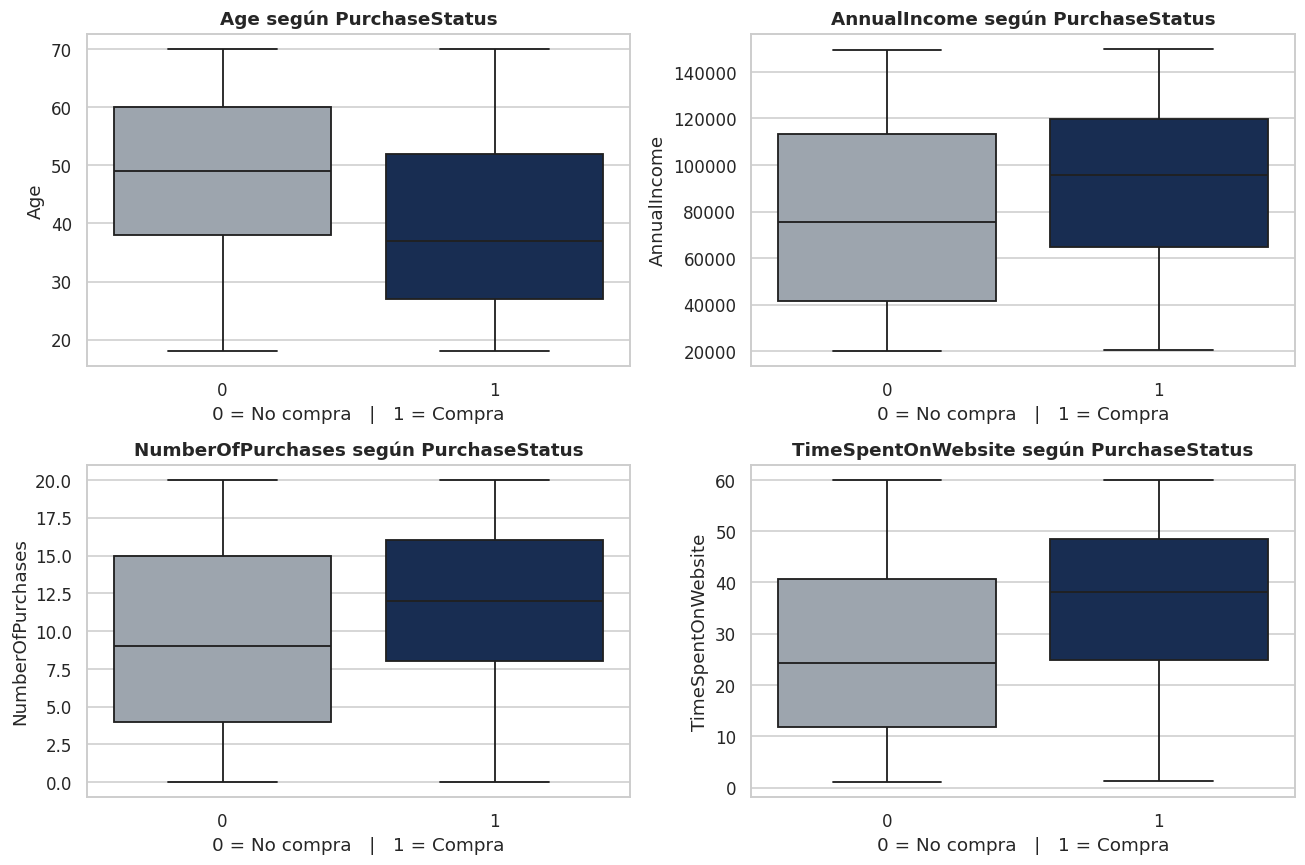

In [ ]:
boxplots_por_target(df, COLS_NUM, TARGET, n_cols=2)

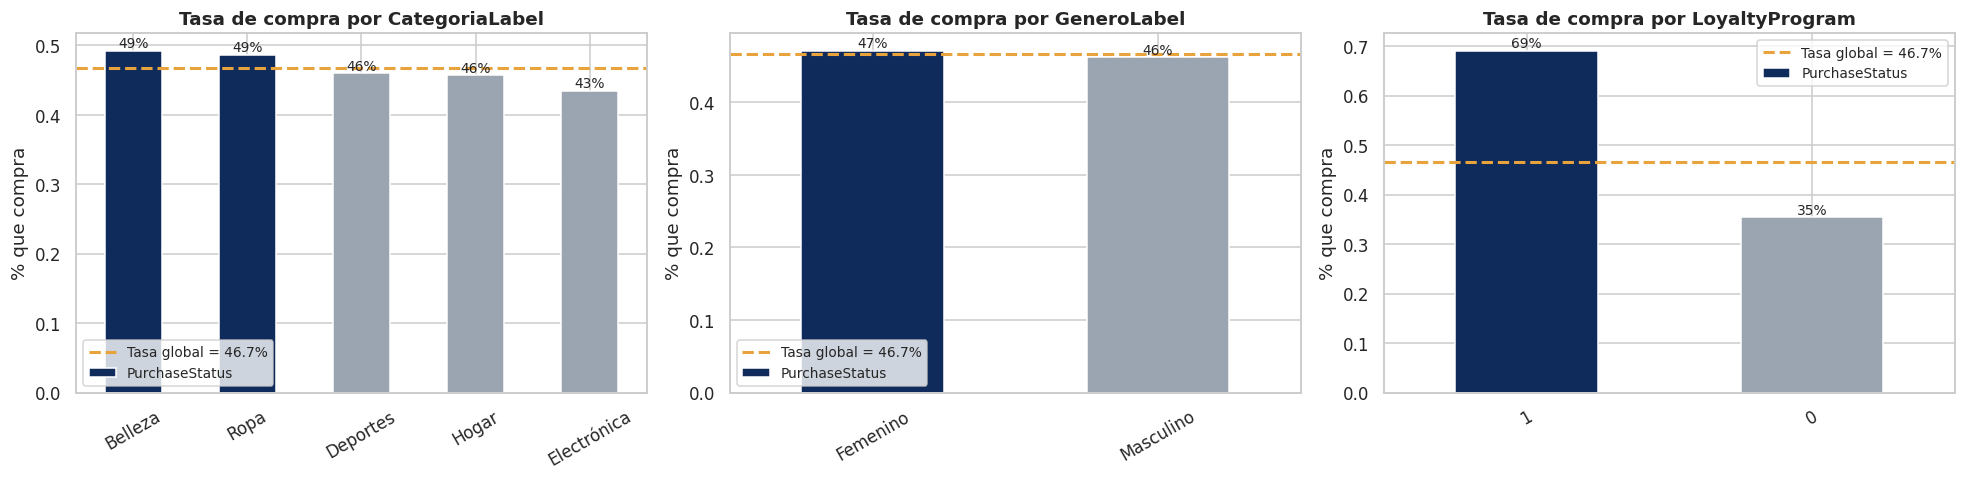

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ['CategoriaLabel', 'GeneroLabel', 'LoyaltyProgram']):
    tasa_por_categoria(df, col, TARGET, ax=ax)
plt.tight_layout()
plt.show()

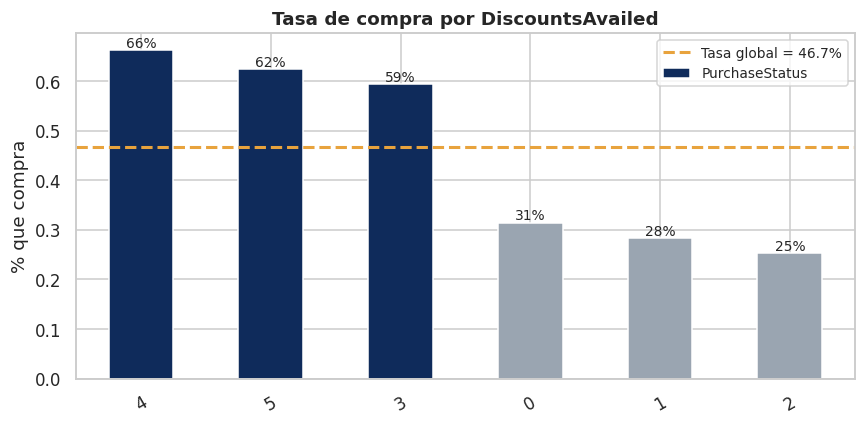

In [ ]:
tasa_por_categoria(df, 'DiscountsAvailed', TARGET)
plt.tight_layout(); plt.show()

**Lectura del bivariado.** Tres señales fuertes: los miembros del programa de fidelización compran
mucho más que los no miembros; el tiempo en el sitio web separa claramente a los dos grupos; y la
tasa de compra crece con el número de descuentos utilizados. En cambio, género y categoría de producto
apenas se mueven alrededor de la tasa global — anticipan poco poder predictivo.

### 4.5 Correlaciones

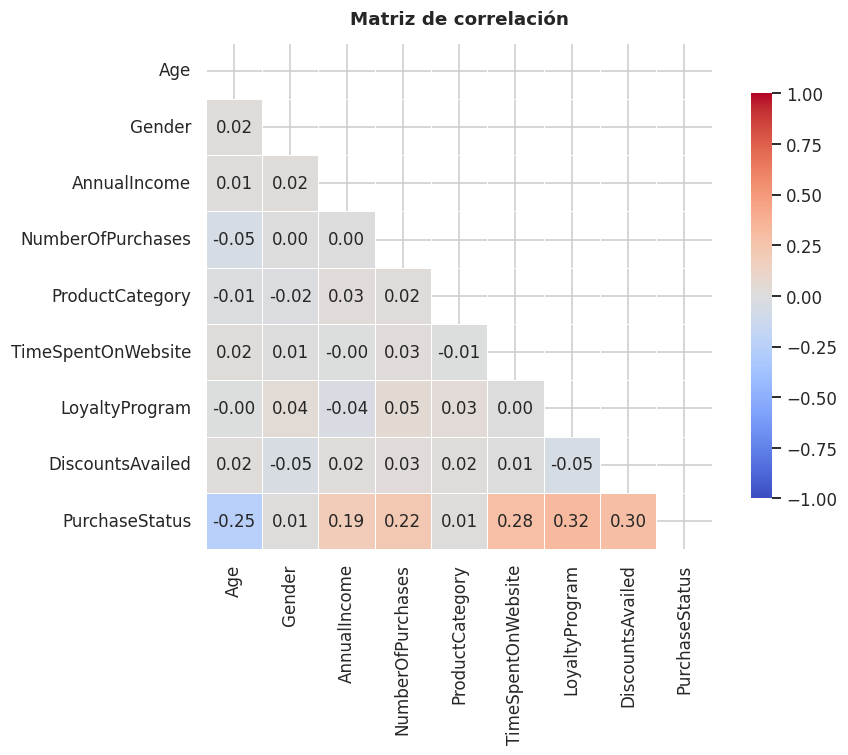

In [ ]:
corr = df.drop(columns=COLS_ETIQUETA).corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=.5, square=True,
            cbar_kws={'shrink': .8})
plt.title('Matriz de correlación', fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

In [ ]:
corr_target = (corr[TARGET]
               .drop(TARGET)
               .sort_values(key=abs, ascending=False)
               .to_frame('Correlación con PurchaseStatus'))
corr_target

,Correlación con PurchaseStatus
LoyaltyProgram,0.3181
DiscountsAvailed,0.2966
TimeSpentOnWebsite,0.2821
Age,-0.2536
NumberOfPurchases,0.2191
AnnualIncome,0.1912
ProductCategory,0.0143
Gender,0.0089


Ninguna correlación entre predictores supera 0.1, así que **no hay multicolinealidad** que preocupe
a la regresión logística. Y la correlación con el objetivo confirma lo que vimos en el bivariado.

> Cuidado: la correlación de Pearson solo captura relaciones **lineales**. Que una variable tenga
> correlación baja no significa que sea inútil — un árbol podría encontrarle valor en una interacción.

## 5. Preparación para el modelado

### 5.1 Separar predictores del objetivo

Convención universal: `X` son las variables explicativas (*features*), `y` es lo que queremos predecir.
Las columnas de etiquetas creadas en la sección 2.3 se eliminan porque duplican información ya
presente en `ProductCategory` y `Gender`.

In [ ]:
df_modelo = df.drop(columns=COLS_ETIQUETA)

X = df_modelo.drop(columns=[TARGET])
y = df_modelo[TARGET]

print(f'X → {X.shape[0]:,} filas × {X.shape[1]} variables')
print(f'y → {y.shape[0]:,} etiquetas')
print(f'\nVariables predictoras: {list(X.columns)}')

X → 1,388 filas × 8 variables
y → 1,388 etiquetas

Variables predictoras: ['Age', 'Gender', 'AnnualIncome', 'NumberOfPurchases', 'ProductCategory', 'TimeSpentOnWebsite', 'LoyaltyProgram', 'DiscountsAvailed']


### 5.2 Partición train / test

**Este es el paso conceptualmente más importante del cuaderno.**

Separamos los datos en dos conjuntos que nunca se mezclan:

- **Train (70%)** — el modelo ve estos datos y ajusta sus parámetros con ellos.
- **Test (30%)** — el modelo *nunca* los ve durante el entrenamiento. Sirven para simular
  clientes nuevos y estimar el desempeño real.

Sin esta separación no hay forma de distinguir un modelo que **aprendió** de uno que **memorizó**.
Un modelo puede alcanzar 100% de accuracy sobre los datos que ya vio simplemente guardándoselos
de memoria, y fallar por completo con el primer cliente nuevo.

Dos argumentos que no son opcionales:

- `stratify=y` — obliga a que la proporción de compradores sea la misma en train y en test.
- `random_state=SEMILLA` — hace la partición reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=SEMILLA,
    stratify=y          # conserva la proporción de la clase objetivo
)

resumen_particion = pd.DataFrame({
    'Clientes':          [len(X_train), len(X_test)],
    '% del total':       [len(X_train) / len(X) * 100, len(X_test) / len(X) * 100],
    'Tasa de compra':    [y_train.mean(), y_test.mean()],
}, index=['Train', 'Test']).round(3)

print(resumen_particion.to_string())
print('\n→ La tasa de compra es prácticamente idéntica en ambos conjuntos: la estratificación funcionó.')

       Clientes  % del total  Tasa de compra
Train       971      69.9570          0.4670
Test        417      30.0430          0.4680

→ La tasa de compra es prácticamente idéntica en ambos conjuntos: la estratificación funcionó.


## 6. Modelo 1 — Regresión logística

Empezamos por el modelo de clasificación **más simple**. Esto no es una limitación: es la práctica
correcta. La regresión logística será nuestra **línea base** (*baseline*), el número que cualquier
modelo más complejo tendrá que superar para justificar su costo de interpretabilidad.

La regresión logística estima la probabilidad de que un cliente compre mediante la función sigmoide:

$$P(\text{compra}) = \frac{e^{\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k}}{1 + e^{\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k}}$$

La salida está siempre entre 0 y 1, y por defecto se clasifica como "compra" si supera **0.5**.
Ese 0.5 es una convención, no una ley — lo cuestionaremos en la sección 10.

### 6.1 Entrenamiento

La regresión logística **sí requiere escalar** las variables: `AnnualIncome` está en decenas de miles
y `DiscountsAvailed` va de 0 a 5. Sin escalar, el algoritmo de optimización converge mal y los
coeficientes no son comparables entre sí.

Usamos un `Pipeline` para encadenar el escalado y el modelo. Su ventaja no es estética: el escalador
se ajusta **solo con los datos de train**, y al predecir sobre test aplica esa misma transformación.
Si escaláramos todo el dataset antes de partir, información del test se filtraría al entrenamiento
(*data leakage*) y las métricas quedarían contaminadas.

In [ ]:
modelo_log = Pipeline([
    ('escalador', StandardScaler()),
    ('clasificador', LogisticRegression(max_iter=1000, random_state=SEMILLA))
])

modelo_log.fit(X_train, y_train)
print('Modelo entrenado.')
print(f'Intercepto (β₀): {modelo_log.named_steps["clasificador"].intercept_[0]:.4f}')

Modelo entrenado.
Intercepto (β₀): -0.2188


### 6.2 Los indicadores: train vs. test

Aquí aplicamos la regla del curso. La función `evaluar_modelo` devuelve las ocho métricas
de la sesión calculadas **en los dos conjuntos**, para que la comparación esté siempre a la vista.

In [ ]:
res_log = evaluar_modelo(modelo_log, X_train, y_train, X_test, y_test,
                         nombre='Regresión logística', entrenar=False)
res_log.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Regresión logística,0.8126,0.8045,0.7903,0.8320,0.7973,0.8984,0.7968
Test,Regresión logística,0.8106,0.7900,0.8103,0.8108,0.8000,0.8746,0.7493


In [ ]:
for m in ['Accuracy', 'Recall', 'AUC']:
    diagnostico_sobreajuste(res_log, metrica=m)
    print()

Accuracy       Train = 0.813   Test = 0.811   Brecha = +0.002
✅ Generaliza bien — la brecha es aceptable

Recall         Train = 0.790   Test = 0.810   Brecha = -0.020
✅ Generaliza bien — la brecha es aceptable

AUC            Train = 0.898   Test = 0.875   Brecha = +0.024
✅ Generaliza bien — la brecha es aceptable



**Cómo leer esta tabla.**

Las métricas de train y test son prácticamente iguales — la brecha en accuracy es de menos de medio punto.
Eso significa que el modelo **no memorizó**: lo que aprendió en los datos de entrenamiento se traslada
igual de bien a clientes que nunca vio. Es un modelo estable, aunque todavía no sabemos si es bueno;
para eso necesitamos algo con qué compararlo.

Recordatorio de qué mide cada indicador, en el lenguaje del caso:

| Métrica | Fórmula | Qué responde en Vitrina |
|---|---|---|
| **Accuracy** | (TP+TN)/total | ¿Qué porcentaje de clientes clasifiqué bien? |
| **Precision** | TP/(TP+FP) | De los que contacté, ¿qué % realmente compró? |
| **Recall** | TP/(TP+FN) | De todos los compradores, ¿a qué % alcancé a contactar? |
| **Especificidad** | TN/(TN+FP) | De los que no compran, ¿a qué % correctamente dejé fuera? |
| **F1** | media armónica | Equilibrio entre precision y recall |
| **AUC** | área bajo ROC | ¿Qué tan bien **ordena** el modelo, sin fijar un corte? |
| **Gini** | 2·AUC − 1 | Lo mismo que AUC, en la escala que usa el sector financiero |

### 6.3 Matriz de confusión

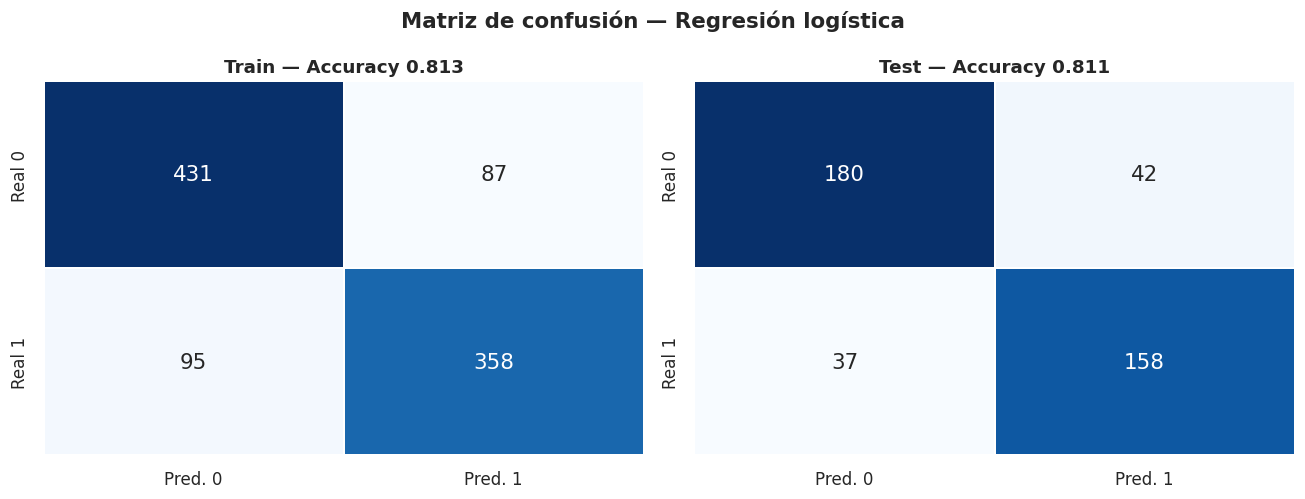

In [ ]:
graficar_matrices_confusion(modelo_log, X_train, y_train, X_test, y_test,
                            nombre='Regresión logística')

In [ ]:
print('REPORTE DE CLASIFICACIÓN — TEST\n')
print(classification_report(y_test, modelo_log.predict(X_test),
                            target_names=['No compra', 'Compra']))

REPORTE DE CLASIFICACIÓN — TEST

              precision    recall  f1-score   support

   No compra       0.83      0.81      0.82       222
      Compra       0.79      0.81      0.80       195

    accuracy                           0.81       417
   macro avg       0.81      0.81      0.81       417
weighted avg       0.81      0.81      0.81       417



En la matriz de test, la celda inferior izquierda son los **falsos negativos**: compradores reales
que el modelo dejó fuera de la lista. Son, en este caso, el error caro.

### 6.4 Curva ROC

La curva ROC evalúa el modelo **en todos los puntos de corte a la vez**. Por eso el AUC es la métrica
más robusta para comparar modelos: no depende de dónde hayamos puesto el umbral.

Cuando las curvas de train y test se superponen, el modelo generaliza. Cuando la de train se pega
a la esquina superior izquierda y la de test se queda muy abajo, hay sobreajuste.

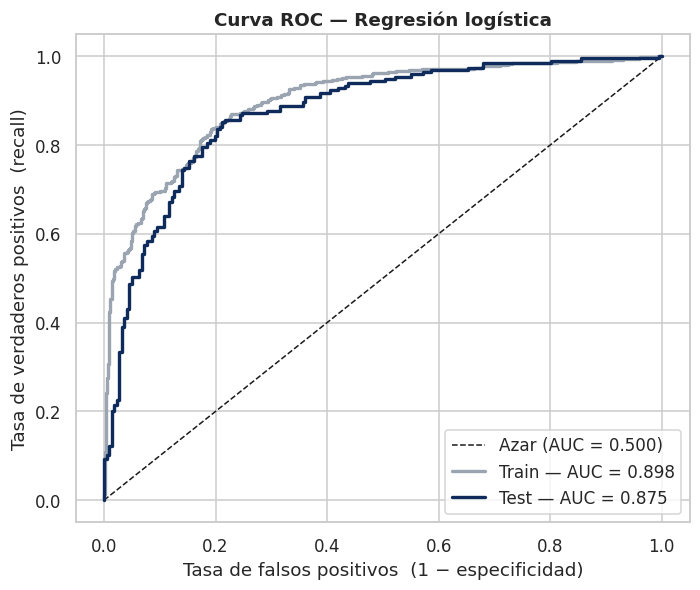

In [ ]:
graficar_roc(modelo_log, X_train, y_train, X_test, y_test,
             nombre='Regresión logística')

### 6.5 Interpretación de los coeficientes

Esta es la gran ventaja de la regresión logística sobre modelos más complejos: cada coeficiente
tiene una lectura directa. Como escalamos las variables, los coeficientes **son comparables entre sí**
y su magnitud indica peso relativo.

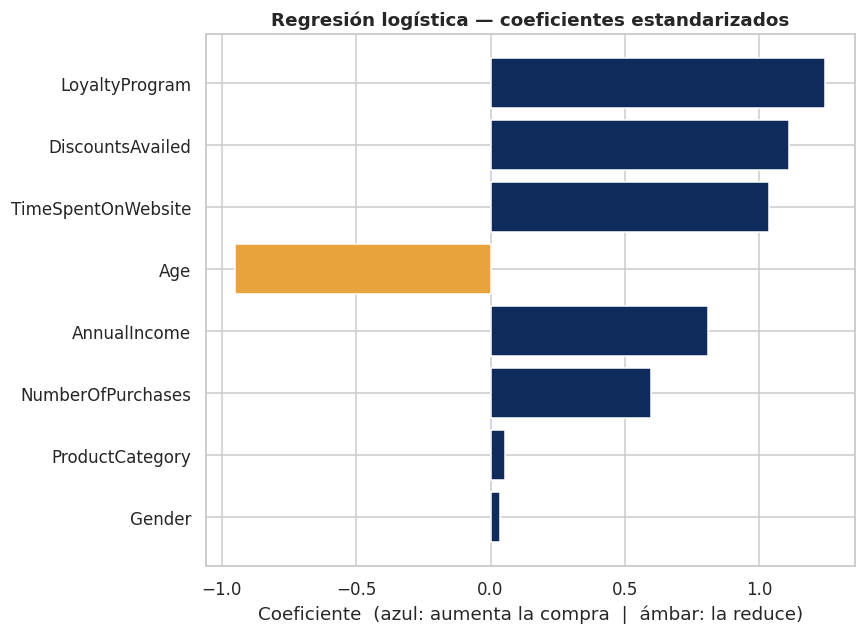

,Variable,Valor,Odds ratio
0,LoyaltyProgram,1.2450,3.4740
1,DiscountsAvailed,1.1100,3.0340
2,TimeSpentOnWebsite,1.0350,2.8160
3,Age,-0.9500,0.3870
4,AnnualIncome,0.8080,2.2440
5,NumberOfPurchases,0.5960,1.8150
6,ProductCategory,0.0550,1.0570
7,Gender,0.0350,1.0360


In [ ]:
coefs = modelo_log.named_steps['clasificador'].coef_[0]

tabla_coefs = graficar_importancias(
    coefs, X_train.columns,
    titulo='Regresión logística — coeficientes estandarizados',
    xlabel='Coeficiente  (azul: aumenta la compra  |  ámbar: la reduce)'
)

tabla_coefs['Odds ratio'] = np.exp(tabla_coefs['Valor'])
tabla_coefs.round(3)

**Lectura de negocio.** Pertenecer al programa de fidelización y haber usado descuentos son los dos
factores que más elevan la probabilidad de compra; el tiempo en el sitio web viene detrás. La edad
aparece con signo negativo: a mayor edad, menor propensión en esta base. Género y categoría de producto
tienen coeficientes cercanos a cero, tal como anticipó el análisis bivariado.

El **odds ratio** (exponencial del coeficiente) se lee así: un valor de 3.5 significa que un aumento
de una desviación estándar en esa variable multiplica por 3.5 las probabilidades relativas de compra.

## 7. Modelo 2 — Árbol de decisión

Un árbol de decisión es una secuencia de preguntas binarias sobre las variables hasta llegar a una
predicción. Es el modelo más intuitivo de explicar a un área no técnica.

Pero tiene un defecto conocido, y lo vamos a provocar deliberadamente para verlo.

### 7.1 Un árbol sin restricciones: el sobreajuste en vivo

Si no limitamos la profundidad, el árbol seguirá dividiendo hasta que cada hoja contenga clientes de
una sola clase. En el límite, memoriza el conjunto de entrenamiento entero.

In [ ]:
arbol_sin_podar = DecisionTreeClassifier(random_state=SEMILLA)   # sin límite de profundidad

res_arbol_full = evaluar_modelo(arbol_sin_podar, X_train, y_train, X_test, y_test,
                                nombre='Árbol sin podar')
res_arbol_full.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Árbol sin podar,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Test,Árbol sin podar,0.8513,0.8152,0.8821,0.8243,0.8473,0.8532,0.7064


In [ ]:
print(f'Profundidad alcanzada: {arbol_sin_podar.get_depth()}')
print(f'Número de hojas: {arbol_sin_podar.get_n_leaves()}\n')

for m in ['Accuracy', 'Recall', 'AUC']:
    diagnostico_sobreajuste(res_arbol_full, metrica=m)
    print()

Profundidad alcanzada: 12
Número de hojas: 116

Accuracy       Train = 1.000   Test = 0.851   Brecha = +0.149
⚠️  SOBREAJUSTE — el modelo memorizó el train

Recall         Train = 1.000   Test = 0.882   Brecha = +0.118
⚠️  SOBREAJUSTE — el modelo memorizó el train

AUC            Train = 1.000   Test = 0.853   Brecha = +0.147
⚠️  SOBREAJUSTE — el modelo memorizó el train



**Este es el resultado más importante del cuaderno.**

Accuracy de **1.000 en train**. El árbol acertó absolutamente todos los casos que vio. Un gerente al que
le muestren solo ese número concluirá que el modelo es perfecto.

Y en test cae unos 15 puntos. El modelo no aprendió el patrón general de qué hace comprar a un cliente:
construyó una regla a medida para cada cliente del entrenamiento. Con datos nuevos, esas reglas no aplican.

**Si solo hubiéramos medido en train, habríamos desplegado un modelo defectuoso convencidos de que era
excelente.** Por eso train y test se reportan siempre juntos.

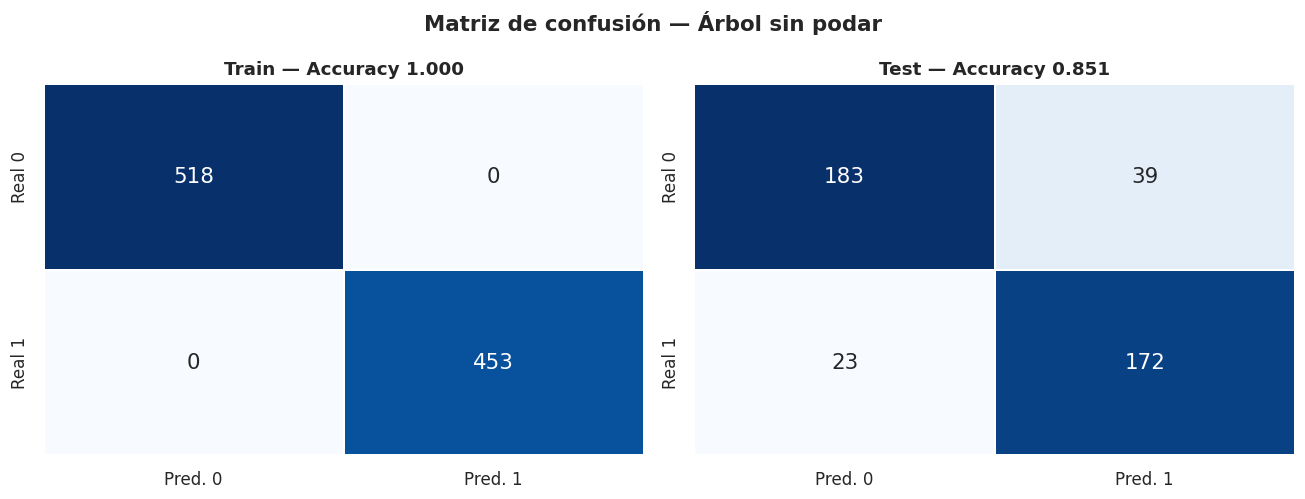

In [ ]:
graficar_matrices_confusion(arbol_sin_podar, X_train, y_train, X_test, y_test,
                            nombre='Árbol sin podar')

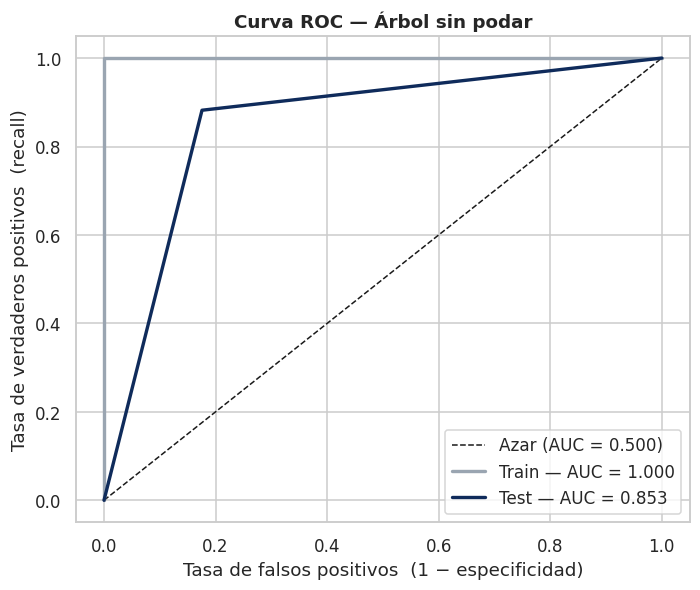

In [ ]:
graficar_roc(arbol_sin_podar, X_train, y_train, X_test, y_test,
             nombre='Árbol sin podar')

La curva de train pasa exactamente por la esquina (AUC = 1.000) y la de test se queda muy por debajo.
Esa separación entre las dos curvas **es** el sobreajuste, dibujado.

### 7.2 Podar el árbol

La solución son los hiperparámetros de control vistos en clase: `max_depth` limita cuántas preguntas
encadena el árbol y `min_samples_leaf` exige un mínimo de clientes por hoja, impidiendo reglas
construidas sobre dos o tres casos.

In [ ]:
arbol = DecisionTreeClassifier(
    max_depth=4,            # como máximo 4 preguntas encadenadas
    min_samples_leaf=30,    # ninguna hoja con menos de 30 clientes
    random_state=SEMILLA
)

res_arbol = evaluar_modelo(arbol, X_train, y_train, X_test, y_test,
                           nombre='Árbol podado')
res_arbol.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Árbol podado,0.8280,0.8004,0.8411,0.8166,0.8202,0.9094,0.8188
Test,Árbol podado,0.8010,0.7745,0.8103,0.7928,0.7920,0.8685,0.7371


In [ ]:
diagnostico_sobreajuste(res_arbol, metrica='Accuracy')

Accuracy       Train = 0.828   Test = 0.801   Brecha = +0.027
✅ Generaliza bien — la brecha es aceptable


np.float64(0.02705312577949992)

La brecha se cerró: el modelo perdió accuracy en train pero **ganó honestidad**. Renunciar a ajuste
en entrenamiento para ganar generalización es exactamente el intercambio que buscamos.

### 7.3 Visualizar las reglas

La razón por la que un árbol sigue siendo útil aunque no sea el más preciso: se puede leer.

In [1]:
plt.figure(figsize=(20, 9))
plot_tree(arbol,
          feature_names=list(X_train.columns),
          class_names=['No fuga', 'Fuga'],
          filled=True, rounded=True, fontsize=9, max_depth=3, impurity=False)
plt.title('Árbol de decisión — primeros 3 niveles', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

Cada nodo se lee como una regla de negocio directa: *"si el cliente pasó más de X minutos en el sitio
y pertenece al programa de fidelización, entonces compra con alta probabilidad"*. Eso se puede llevar
a un comité sin explicar nada de machine learning.

## 8. Modelo 3 — Random Forest

Random Forest entrena muchos árboles sobre muestras distintas de los datos y promedia sus votos.
La idea: un árbol individual sobreajusta, pero el **promedio de cientos de árboles que sobreajustan
de formas distintas** cancela buena parte de ese error.

In [ ]:
modelo_rf = RandomForestClassifier(
    n_estimators=300,       # 300 árboles en el bosque
    max_depth=8,            # profundidad máxima de cada árbol
    min_samples_leaf=10,    # mínimo de clientes por hoja
    random_state=SEMILLA,
    n_jobs=-1               # usa todos los núcleos disponibles
)

res_rf = evaluar_modelo(modelo_rf, X_train, y_train, X_test, y_test,
                        nombre='Random Forest')
res_rf.round(4)

,Modelo,Accuracy,Precision,Recall,Especificidad,F1,AUC,Gini
Partición,,,,,,,,
Train,Random Forest,0.9537,0.9636,0.9360,0.9691,0.9496,0.9688,0.9376
Test,Random Forest,0.9185,0.9128,0.9128,0.9234,0.9128,0.9379,0.8758


In [ ]:
for m in ['Accuracy', 'Recall', 'AUC']:
    diagnostico_sobreajuste(res_rf, metrica=m)
    print()

Accuracy       Train = 0.954   Test = 0.918   Brecha = +0.035
✅ Generaliza bien — la brecha es aceptable

Recall         Train = 0.936   Test = 0.913   Brecha = +0.023
✅ Generaliza bien — la brecha es aceptable

AUC            Train = 0.969   Test = 0.938   Brecha = +0.031
✅ Generaliza bien — la brecha es aceptable



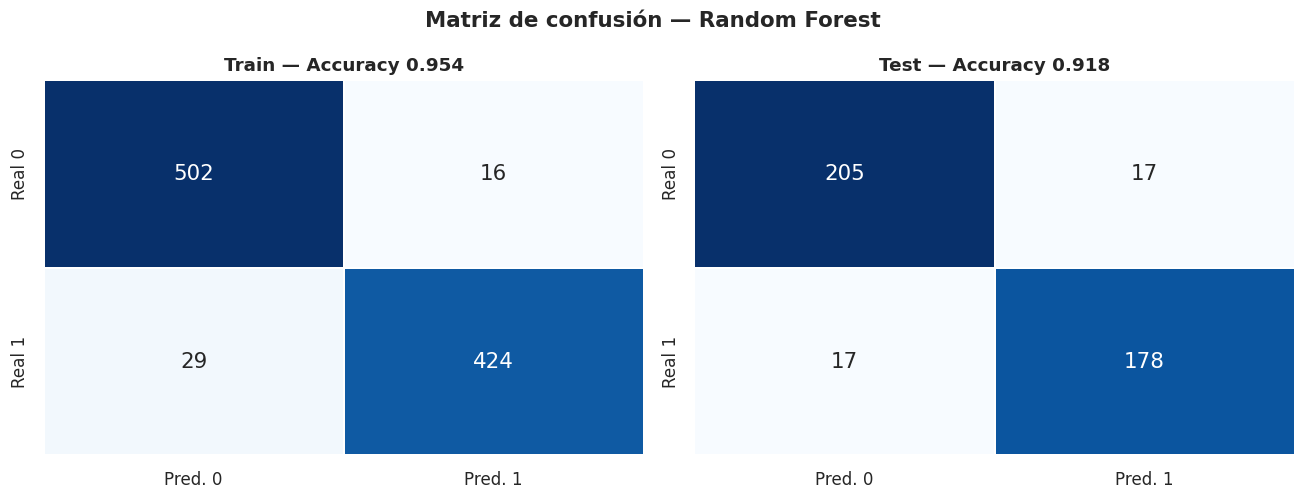

In [ ]:
graficar_matrices_confusion(modelo_rf, X_train, y_train, X_test, y_test,
                            nombre='Random Forest')

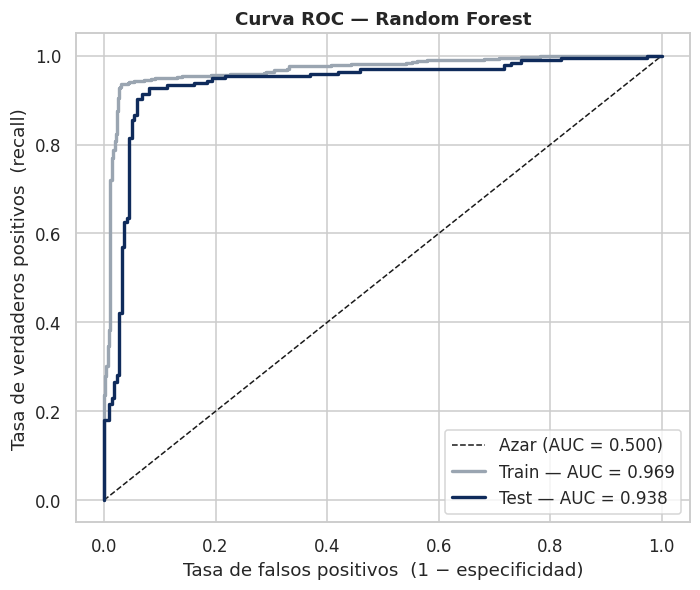

In [ ]:
graficar_roc(modelo_rf, X_train, y_train, X_test, y_test, nombre='Random Forest')

### 8.1 Importancia de las variables

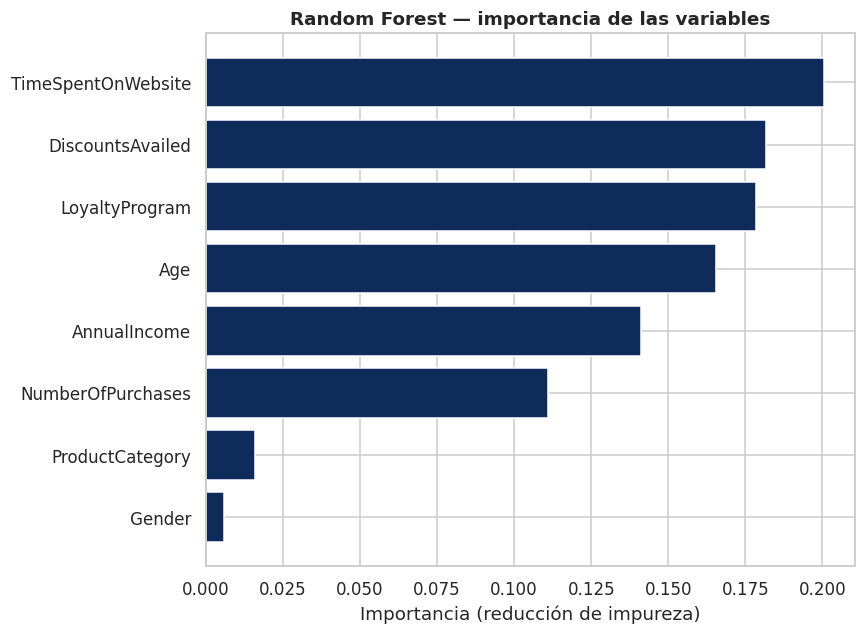

,Variable,Valor
0,TimeSpentOnWebsite,0.2004
1,DiscountsAvailed,0.1817
2,LoyaltyProgram,0.1784
3,Age,0.1654
4,AnnualIncome,0.1411
5,NumberOfPurchases,0.1110
6,ProductCategory,0.0158
7,Gender,0.0060


In [ ]:
tabla_imp = graficar_importancias(
    modelo_rf.feature_importances_, X_train.columns,
    titulo='Random Forest — importancia de las variables',
    xlabel='Importancia (reducción de impureza)'
)
tabla_imp.round(4)

El ranking coincide con el de la regresión logística: tiempo en el sitio, descuentos utilizados,
programa de fidelización y edad concentran casi todo el poder predictivo. Que dos modelos con lógicas
internas completamente distintas lleguen al mismo orden es una **buena señal de robustez**.

Ojo con la diferencia de interpretación: la importancia de Random Forest indica *cuánto aporta* una
variable, pero **no en qué dirección** — para eso hay que mirar los coeficientes de la logística.

## 9. Comparación de los tres modelos

Ahora sí, todo junto. Un modelo no se elige por su número más alto, sino por el equilibrio entre
desempeño en test, brecha respecto de train, e interpretabilidad.

In [ ]:
comparacion = pd.concat([res_log, res_arbol_full, res_arbol, res_rf])
comparacion = comparacion.reset_index().set_index(['Modelo', 'Partición'])
comparacion.round(4)

Accuracy  Precision  Recall  Especificidad  \
Modelo              Partición                                               
Regresión logística Train        0.8126     0.8045  0.7903         0.8320   
                    Test         0.8106     0.7900  0.8103         0.8108   
Árbol sin podar     Train        1.0000     1.0000  1.0000         1.0000   
                    Test         0.8513     0.8152  0.8821         0.8243   
Árbol podado        Train        0.8280     0.8004  0.8411         0.8166   
                    Test         0.8010     0.7745  0.8103         0.7928   
Random Forest       Train        0.9537     0.9636  0.9360         0.9691   
                    Test         0.9185     0.9128  0.9128         0.9234   

                                  F1    AUC   Gini  
Modelo              Partición                       
Regresión logística Train     0.7973 0.8984 0.7968  
                    Test      0.8000 0.8746 0.7493  
Árbol sin podar     Train     1.0000 1.0000 1.0000  
                    Test      0.8473 0.8532 0.7064  
Árbol podado        Train     0.8202 0.9094 0.8188  
                    Test      0.7920 0.8685 0.7371  
Random Forest       Train     0.9496 0.9688 0.9376  
                    Test      0.9128 0.9379 0.8758

In [ ]:
# Brecha train − test por modelo: el termómetro del sobreajuste
brechas = (comparacion.reset_index()
           .pivot(index='Modelo', columns='Partición',
                  values=['Accuracy', 'AUC']))

resumen = pd.DataFrame({
    'Accuracy Train': brechas[('Accuracy', 'Train')],
    'Accuracy Test':  brechas[('Accuracy', 'Test')],
    'Brecha Acc':     brechas[('Accuracy', 'Train')] - brechas[('Accuracy', 'Test')],
    'AUC Test':       brechas[('AUC', 'Test')],
    'Gini Test':      2 * brechas[('AUC', 'Test')] - 1,
}).sort_values('AUC Test', ascending=False)

resumen.round(4)

,Accuracy Train,Accuracy Test,Brecha Acc,AUC Test,Gini Test
Modelo,,,,,
Random Forest,0.9537,0.9185,0.0352,0.9379,0.8758
Regresión logística,0.8126,0.8106,0.0020,0.8746,0.7493
Árbol podado,0.8280,0.8010,0.0271,0.8685,0.7371
Árbol sin podar,1.0000,0.8513,0.1487,0.8532,0.7064


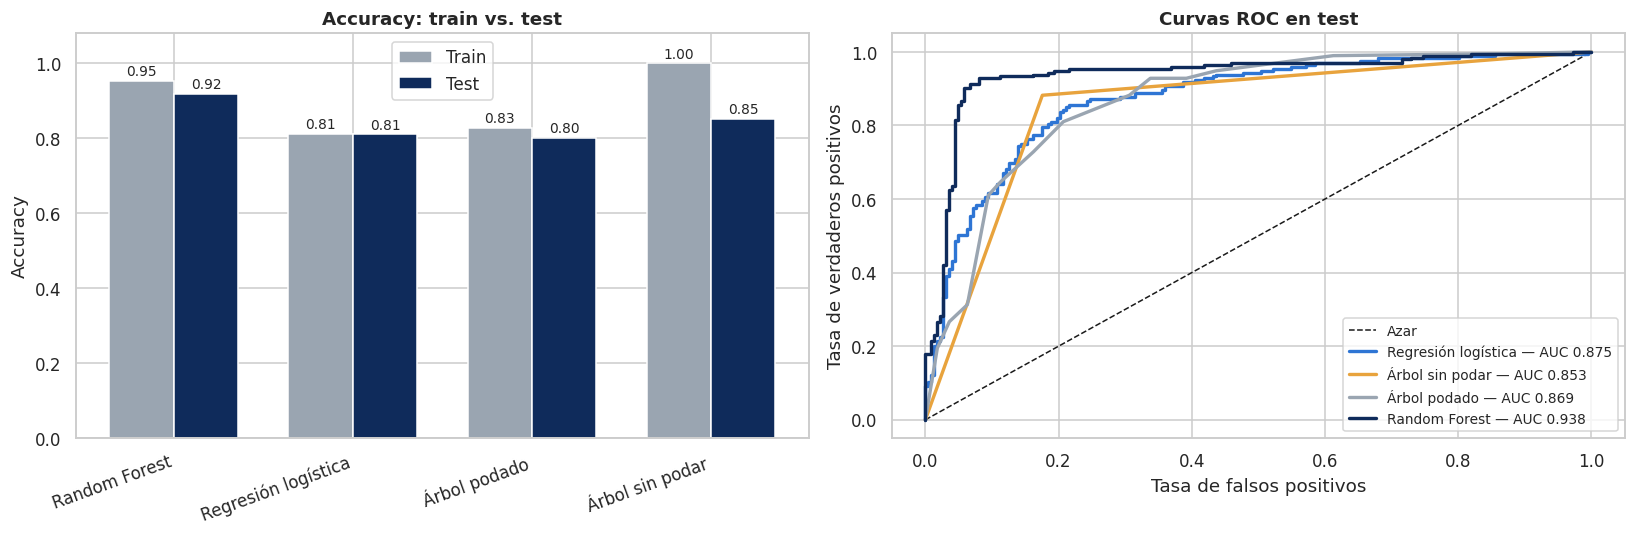

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel izquierdo: accuracy train vs test
orden = resumen.index
x = np.arange(len(orden)); ancho = 0.36
axes[0].bar(x - ancho/2, resumen['Accuracy Train'], ancho, label='Train', color=GRIS)
axes[0].bar(x + ancho/2, resumen['Accuracy Test'],  ancho, label='Test',  color=AZUL)
axes[0].set_xticks(x); axes[0].set_xticklabels(orden, rotation=20, ha='right')
axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0, 1.08)
axes[0].set_title('Accuracy: train vs. test', fontweight='bold')
axes[0].legend()
for i, (tr, te) in enumerate(zip(resumen['Accuracy Train'], resumen['Accuracy Test'])):
    axes[0].text(i - ancho/2, tr + .015, f'{tr:.2f}', ha='center', fontsize=9)
    axes[0].text(i + ancho/2, te + .015, f'{te:.2f}', ha='center', fontsize=9)

# Panel derecho: curvas ROC de test superpuestas
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Azar')
for (nombre, mdl), color in zip(
        [('Regresión logística', modelo_log), ('Árbol sin podar', arbol_sin_podar),
         ('Árbol podado', arbol), ('Random Forest', modelo_rf)],
        [AZUL_CLARO, AMBAR, GRIS, AZUL]):
    proba = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, lw=2.2, color=color,
                 label=f'{nombre} — AUC {roc_auc_score(y_test, proba):.3f}')
axes[1].set_xlabel('Tasa de falsos positivos'); axes[1].set_ylabel('Tasa de verdaderos positivos')
axes[1].set_title('Curvas ROC en test', fontweight='bold')
axes[1].legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

### Decisión

El panel izquierdo muestra por qué la comparación train–test no es un formalismo. El **árbol sin podar**
tiene la barra de train más alta de todas y es, sin embargo, el peor candidato: toda esa altura es memoria,
no aprendizaje.

**Random Forest** es el modelo elegido: mejor AUC en test y una brecha contenida frente a train.
La **regresión logística** se conserva como referencia interpretable — pierde algunos puntos de AUC,
pero explica *por qué* clasifica como clasifica, lo que la hace preferible cuando hay que justificar
decisiones ante un comité o un regulador.

## 10. El punto de corte

Hasta aquí usamos el umbral por defecto de 0.5. Pero el modelo no entrega una clase: entrega una
**probabilidad**. El 0.5 es una decisión de negocio disfrazada de configuración técnica.

Mover el umbral no cambia el modelo. Cambia el balance entre los dos tipos de error:

- **Umbral alto (0.8)** → contactamos a pocos, casi todos compran. Alta precision, bajo recall.
  Perdemos compradores por no llamarlos.
- **Umbral bajo (0.3)** → contactamos a muchos, capturamos casi todos los compradores.
  Alto recall, baja precision. Gastamos cupones en gente que no iba a comprar.

In [ ]:
proba_test = modelo_rf.predict_proba(X_test)[:, 1]

tabla_umbral = barrido_umbral(y_test, proba_test)
tabla_umbral.round(3)

,Umbral,Contactados,TP,FP,FN,TN,Precision,Recall,F1
0,0.1000,386,194,192,1,30,0.5030,0.9950,0.6680
1,0.1500,357,192,165,3,57,0.5380,0.9850,0.6960
2,0.2000,319,189,130,6,92,0.5920,0.9690,0.7350
3,0.2500,288,188,100,7,122,0.6530,0.9640,0.7780
4,0.3000,269,187,82,8,140,0.6950,0.9590,0.8060
5,0.3500,248,186,62,9,160,0.7500,0.9540,0.8400
6,0.4000,225,184,41,11,181,0.8180,0.9440,0.8760
7,0.4500,206,181,25,14,197,0.8790,0.9280,0.9030
8,0.5000,195,178,17,17,205,0.9130,0.9130,0.9130
9,0.5500,181,169,12,26,210,0.9340,0.8670,0.8990


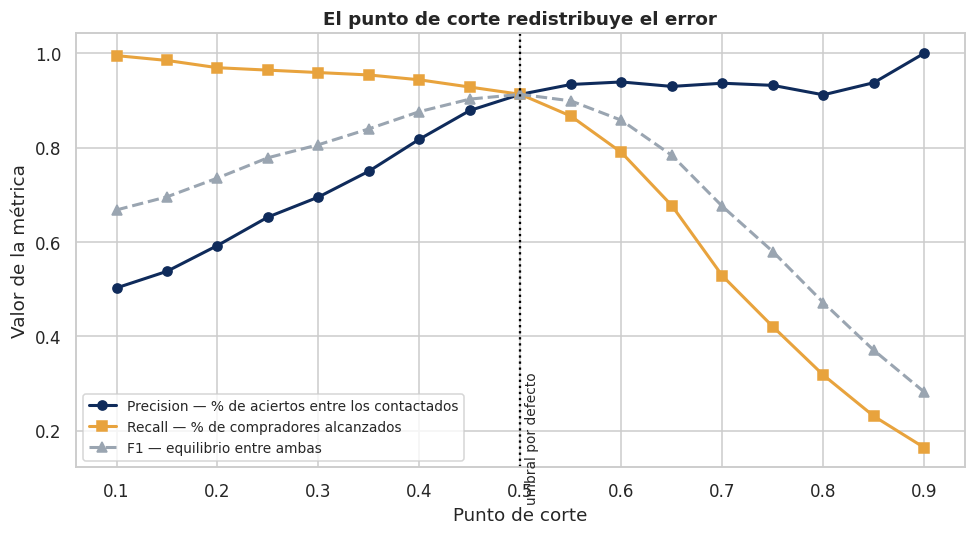

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(tabla_umbral['Umbral'], tabla_umbral['Precision'], 'o-', color=AZUL,
        lw=2, label='Precision — % de aciertos entre los contactados')
ax.plot(tabla_umbral['Umbral'], tabla_umbral['Recall'], 's-', color=AMBAR,
        lw=2, label='Recall — % de compradores alcanzados')
ax.plot(tabla_umbral['Umbral'], tabla_umbral['F1'], '^--', color=GRIS,
        lw=2, label='F1 — equilibrio entre ambas')
ax.axvline(0.5, color='black', ls=':', lw=1.5)
ax.text(0.505, 0.05, 'umbral por defecto', fontsize=9, rotation=90)
ax.set_xlabel('Punto de corte'); ax.set_ylabel('Valor de la métrica')
ax.set_title('El punto de corte redistribuye el error', fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Cómo elegirlo en este caso.** Vitrina tiene capacidad para 150 contactos semanales, no para todos
los que superen 0.5. Cuando la restricción es de capacidad, el umbral deja de ser la herramienta
adecuada: lo correcto es **ordenar por score y cortar donde se acaba el presupuesto**. Eso es lo que
hacemos en la siguiente sección.

## 11. Del modelo a la decisión

Un modelo que se queda en la tabla de métricas no genera valor. Traducimos el score a la lógica
que el área comercial usa todos los días: **deciles**.

### 11.1 Tabla de deciles

Ordenamos toda la base de test por score de mayor a menor, la partimos en diez grupos iguales y
medimos la tasa de compra real de cada uno. El **lift** indica cuántas veces mejor es cada decil
respecto de elegir al azar.

In [ ]:
deciles = tabla_deciles(y_test, proba_test)
deciles.round(3)

,Clientes,Compradores,Tasa_compra,Score_min,Score_max,Lift,Captura_acum_%
Decil,,,,,,,
1,42,40,0.9520,0.8680,0.9590,2.0370,20.5130
2,42,38,0.9050,0.7600,0.8650,1.9350,40.0000
3,41,39,0.9510,0.6860,0.7600,2.0340,60.0000
4,42,40,0.9520,0.5910,0.6850,2.0370,80.5130
5,41,25,0.6100,0.4470,0.5900,1.3040,93.3330
6,42,4,0.0950,0.3430,0.4430,0.2040,95.3850
7,42,3,0.0710,0.2450,0.3400,0.1530,96.9230
8,41,0,0.0000,0.1810,0.2440,0.0000,96.9230
9,42,4,0.0950,0.1230,0.1800,0.2040,98.9740


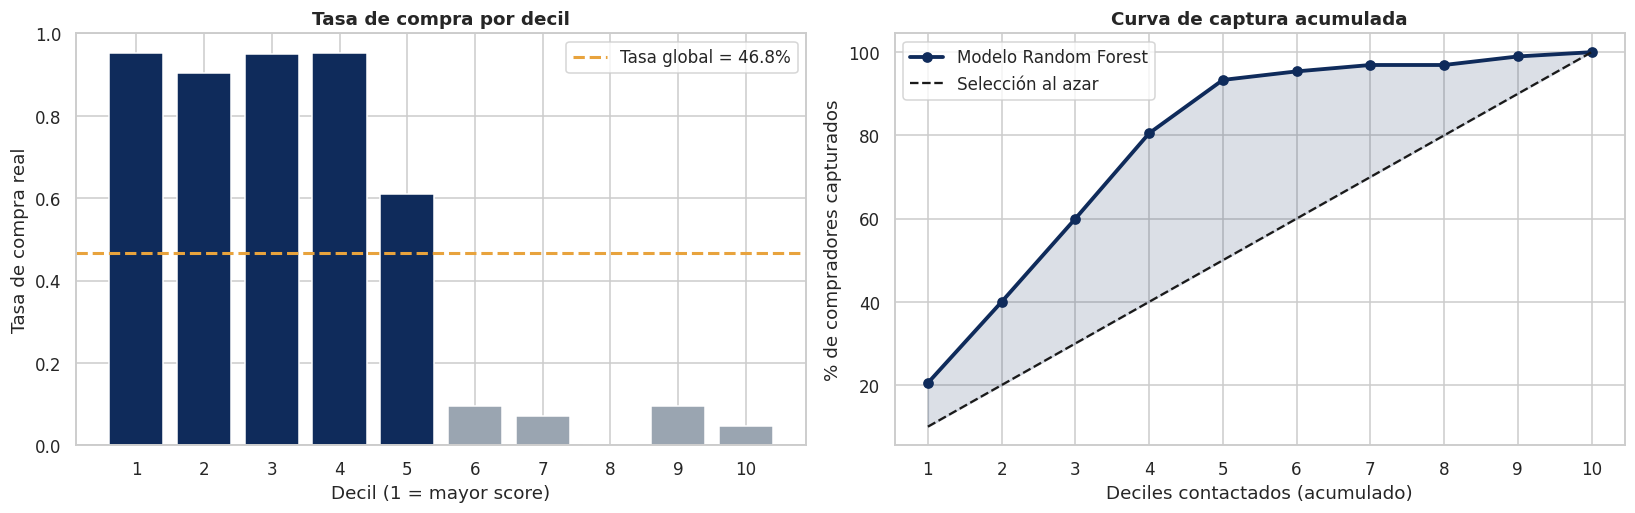

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Tasa de compra por decil
colores = [AZUL if v >= 1 else GRIS for v in deciles['Lift']]
axes[0].bar(deciles.index, deciles['Tasa_compra'], color=colores, edgecolor='white')
axes[0].axhline(y_test.mean(), color=AMBAR, ls='--', lw=2,
                label=f'Tasa global = {y_test.mean():.1%}')
axes[0].set_xlabel('Decil (1 = mayor score)'); axes[0].set_ylabel('Tasa de compra real')
axes[0].set_title('Tasa de compra por decil', fontweight='bold')
axes[0].set_xticks(deciles.index); axes[0].legend()

# Curva de captura acumulada
axes[1].plot(deciles.index, deciles['Captura_acum_%'], 'o-', color=AZUL, lw=2.5,
             label='Modelo Random Forest')
axes[1].plot(deciles.index, np.arange(10, 101, 10), 'k--', lw=1.5,
             label='Selección al azar')
axes[1].fill_between(deciles.index, np.arange(10, 101, 10),
                     deciles['Captura_acum_%'], alpha=.15, color=AZUL)
axes[1].set_xlabel('Deciles contactados (acumulado)')
axes[1].set_ylabel('% de compradores capturados')
axes[1].set_title('Curva de captura acumulada', fontweight='bold')
axes[1].set_xticks(deciles.index); axes[1].legend()

plt.tight_layout()
plt.show()

### 11.2 El impacto de la campaña

La pregunta del gerente comercial era concreta: con capacidad para 150 contactos, ¿cuántos compradores
más consigue el modelo frente a una lista armada al azar?

In [ ]:
CAPACIDAD      = 150     # contactos semanales disponibles
MARGEN_COMPRA  = 180     # margen promedio por compra, en soles
COSTO_CONTACTO = 12      # costo por contacto (cupón + operación), en soles

# Ordenamos la base de test por score y tomamos los primeros 150
ranking = (pd.DataFrame({'score': proba_test, 'compro': y_test.values})
             .sort_values('score', ascending=False)
             .reset_index(drop=True))

seleccion   = ranking.head(CAPACIDAD)
con_modelo  = int(seleccion['compro'].sum())
al_azar     = CAPACIDAD * y_test.mean()

escenarios = pd.DataFrame({
    'Compradores alcanzados': [al_azar, con_modelo],
    'Tasa de conversión':     [y_test.mean(), con_modelo / CAPACIDAD],
    'Margen generado (S/)':   [al_azar * MARGEN_COMPRA, con_modelo * MARGEN_COMPRA],
    'Costo campaña (S/)':     [CAPACIDAD * COSTO_CONTACTO] * 2,
}, index=['Lista al azar', 'Lista del modelo'])
escenarios['Margen neto (S/)'] = (escenarios['Margen generado (S/)']
                                  - escenarios['Costo campaña (S/)'])

print(escenarios.to_string(float_format=lambda v: f'{v:,.2f}'))

extra = con_modelo - al_azar
print(f'\n{"─"*66}')
print(f'Con el mismo presupuesto y la misma capacidad de {CAPACIDAD} contactos:')
print(f'  · Compradores adicionales : {extra:,.0f}')
print(f'  · Lift sobre el azar      : {con_modelo / al_azar:.2f}x')
print(f'  · Margen incremental      : S/ {extra * MARGEN_COMPRA:,.0f} por semana')
print(f'  · Proyección anual (52 s.): S/ {extra * MARGEN_COMPRA * 52:,.0f}')
print(f'{"─"*66}')

                  Compradores alcanzados  Tasa de conversión  Margen generado (S/)  Costo campaña (S/)  Margen neto (S/)
Lista al azar                      70.14                0.47             12,625.90                1800         10,825.90
Lista del modelo                  140.00                0.93             25,200.00                1800         23,400.00

──────────────────────────────────────────────────────────────────
Con el mismo presupuesto y la misma capacidad de 150 contactos:
  · Compradores adicionales : 70
  · Lift sobre el azar      : 2.00x
  · Margen incremental      : S/ 12,574 por semana
  · Proyección anual (52 s.): S/ 653,853
──────────────────────────────────────────────────────────────────


### 11.3 Scoring de la base completa

Finalmente, generamos el entregable operativo: la base con su score y su decil, lista para que
el equipo comercial la cargue en el CRM.

In [ ]:
# Score sobre toda la base (train + test)
base_scoreada = df_modelo.copy()
base_scoreada['Score']      = modelo_rf.predict_proba(X)[:, 1]
base_scoreada['Prediccion'] = (base_scoreada['Score'] >= 0.5).astype(int)
base_scoreada['Decil']      = 11 - pd.qcut(base_scoreada['Score'].rank(method='first'),
                                           10, labels=range(1, 11)).astype(int)
base_scoreada['Prioridad']  = pd.cut(base_scoreada['Decil'], [0, 3, 6, 10],
                                     labels=['Alta', 'Media', 'Baja'])

base_scoreada.sort_values('Score', ascending=False).head(10)

,Age,Gender,AnnualIncome,NumberOfPurchases,ProductCategory,TimeSpentOnWebsite,LoyaltyProgram,DiscountsAvailed,PurchaseStatus,Score,Prediccion,Decil,Prioridad
881,34,1,"102,767.0587",12,3,57.2823,1,5,1,0.9784,1,1,Alta
161,34,1,"102,069.9819",16,4,41.1183,1,5,1,0.9679,1,1,Alta
1077,24,1,"82,795.1607",13,0,35.9860,1,3,1,0.9667,1,1,Alta
158,32,1,"58,387.7642",15,1,36.4358,1,5,1,0.9624,1,1,Alta
6,39,1,"126,883.3853",16,3,42.0854,1,4,1,0.9587,1,1,Alta
390,56,0,"99,951.6858",13,2,33.1945,1,4,1,0.9585,1,1,Alta
592,29,1,"58,153.5470",16,2,59.9911,1,3,1,0.9577,1,1,Alta
704,21,0,"119,595.0713",14,0,44.3509,1,4,1,0.9576,1,1,Alta
49,47,1,"104,216.2680",13,1,56.8493,1,4,1,0.9574,1,1,Alta
1365,55,0,"101,221.9022",14,2,39.3472,1,5,1,0.9557,1,1,Alta


In [ ]:
resumen_prioridad = (base_scoreada
    .groupby('Prioridad', observed=True)
    .agg(Clientes=('Score', 'size'),
         Score_promedio=('Score', 'mean'),
         Tasa_compra_real=(TARGET, 'mean')))

print(resumen_prioridad.round(3).to_string())
print('\n→ El segmento de prioridad Alta es el que recibe la campaña de la próxima semana.')

           Clientes  Score_promedio  Tasa_compra_real
Prioridad                                            
Alta            417          0.8210            0.9660
Media           416          0.5100            0.5220
Baja            555          0.1710            0.0500

→ El segmento de prioridad Alta es el que recibe la campaña de la próxima semana.


> **Advertencia metodológica.** Esta tabla incluye clientes que el modelo usó para entrenar, así que su
> tasa de compra observada es optimista. Sirve como entregable operativo, **no** como evidencia de
> desempeño: para eso valen únicamente las métricas de test de la sección 9.

## 12. Conclusiones

**Sobre el caso**

1. Random Forest fue el modelo seleccionado por su AUC en test, con la regresión logística conservada
   como referencia interpretable.
2. Cuatro variables concentran el poder predictivo: tiempo en el sitio web, descuentos utilizados,
   pertenencia al programa de fidelización y edad. Género y categoría de producto no aportan.
3. Con la misma capacidad de 150 contactos semanales, la lista del modelo duplica la conversión de una
   lista al azar. El costo de la campaña no cambia; cambia a quién se contacta.

**Sobre el método**

4. **Ningún indicador se interpreta solo.** El árbol sin podar alcanzó 100% de accuracy en train y fue
   el peor modelo de todos. La brecha train–test es lo que distingue aprender de memorizar.
5. **La métrica correcta depende del error que duele.** Con capacidad limitada, un falso negativo cuesta
   más que un falso positivo, y eso pesa más que el accuracy global.
6. **El punto de corte es una decisión de negocio.** El 0.5 por defecto no tiene nada de especial; el
   umbral se fija según el costo relativo de cada error o, como aquí, según la capacidad disponible.

---

### Ejercicio propuesto

1. Cambiar `SEMILLA` a otro valor y volver a correr. ¿Cuánto se mueven las métricas de test?
   ¿Qué dice eso sobre la confianza que merece una diferencia de dos décimas entre modelos?
2. Entrenar el árbol podado con `max_depth` de 2 a 15 y graficar accuracy de train y de test contra
   la profundidad. Identificar el punto donde las curvas se separan.
3. Reajustar `CAPACIDAD` a 300 contactos. ¿El lift se mantiene? ¿Por qué disminuye al ampliar la lista?